In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [7]:
df = pd.read_csv(r"C:\Users\91801\Desktop\PROJECTS\Zomato_python\Zomato data .csv")

In [8]:
df

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [9]:
df["rate"] = df["rate"].str.replace("/5", "", regex=False).astype(float)

In [10]:
df

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3,0,100,Dining
144,New Indraprasta,No,No,3.3,0,150,Dining
145,Anna Kuteera,Yes,No,4.0,771,450,Dining
146,Darbar,No,No,3.0,98,800,Dining


In [11]:
df["rate"].dtype

dtype('float64')

### "/5" is the text I want to remove...." " this empty quotes suggest I want to replace it with nothing....regex=False tells pandas to treat /5 as an ordinary text, not as a regular expression

### .astype(float) has converted the rate column in float 

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   name                         148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


# Type of the Restaurants

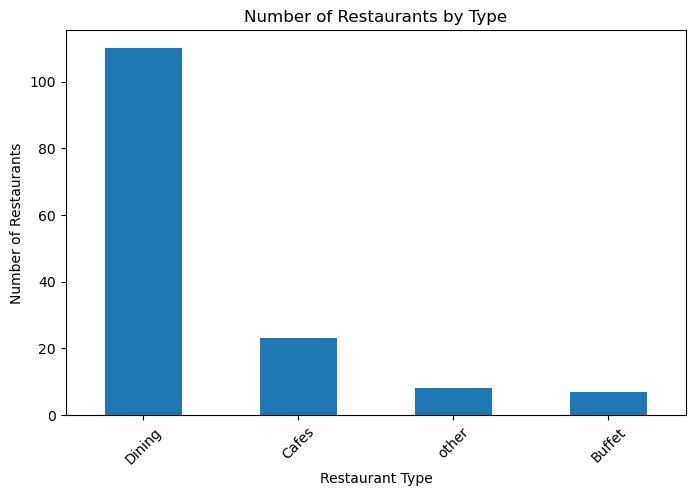

In [13]:
# Count each restaurant type
type_count = df["listed_in(type)"].value_counts()

# Bar graph
plt.figure(figsize=(8,5))
type_count.plot(kind="bar")

plt.title("Number of Restaurants by Type")
plt.xlabel("Restaurant Type")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.show()

### Dining restaurants are preffered by majority of individuals

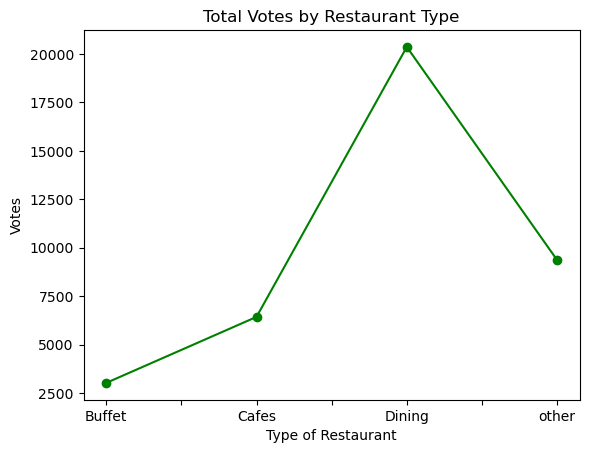

In [14]:
df.groupby("listed_in(type)")["votes"].sum().plot(kind="line", marker="o", color="green")

plt.xlabel("Type of Restaurant")
plt.ylabel("Votes")
plt.title("Total Votes by Restaurant Type")
plt.show()

### Dining restaurants have received the highest total number of votes (around 20,000). 
### Other restaurant types come next (around 9,500).
### Cafes have around 6,500 votes.
### Buffet restaurants have the fewest total votes (around 3,000).
### So this graph is not showing the number of restaurants. It is showing the sum of votes received by each restaurant category.

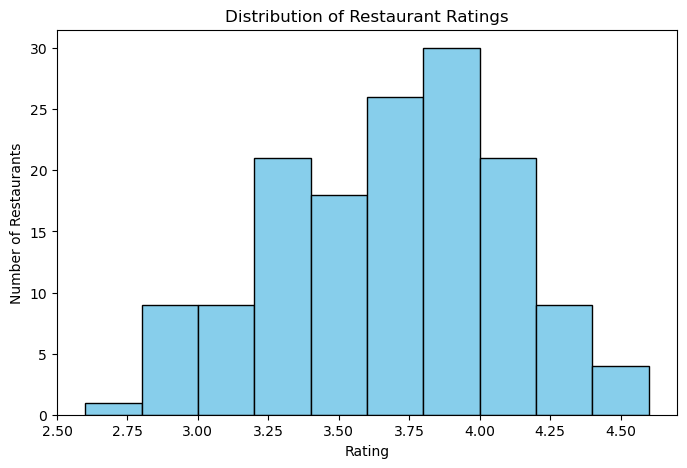

In [15]:
plt.figure(figsize=(8,5))

plt.hist(df["rate"], bins=10, color="skyblue", edgecolor="black")

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")

plt.show()

### Majority of restaurants have received rating between 3.5 to 4

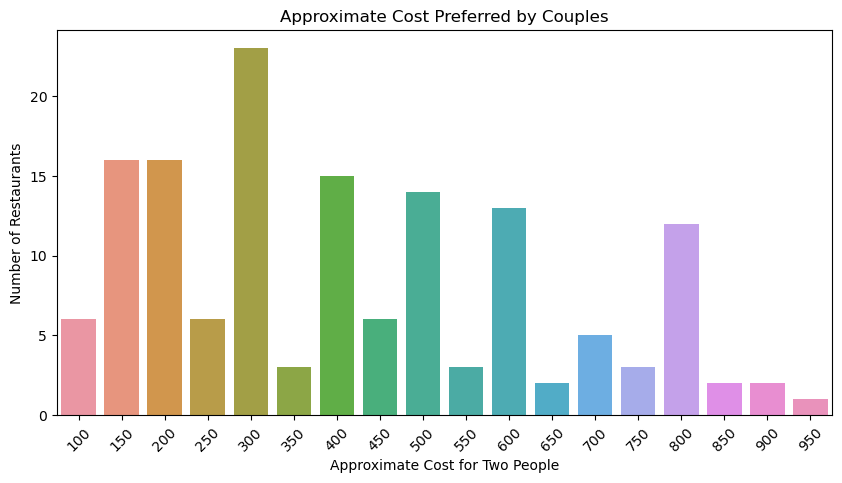

In [16]:
plt.figure(figsize=(10,5))

sns.countplot(x="approx_cost(for two people)", data=df)

plt.title("Approximate Cost Preferred by Couples")
plt.xlabel("Approximate Cost for Two People")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.show()

### Couples mostly prefer restaurants where the approx cost is 300

In [17]:
rating = df.groupby("online_order")["rate"].mean()

print(rating)

online_order
No     3.487778
Yes    3.858621
Name: rate, dtype: float64


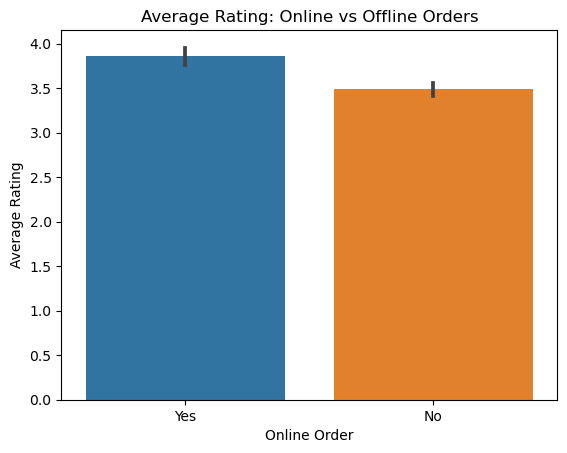

In [18]:
sns.barplot(x="online_order", y="rate", data=df)

plt.title("Average Rating: Online vs Offline Orders")
plt.xlabel("Online Order")
plt.ylabel("Average Rating")

plt.show()

### online orders receive more  ratings than offline orders

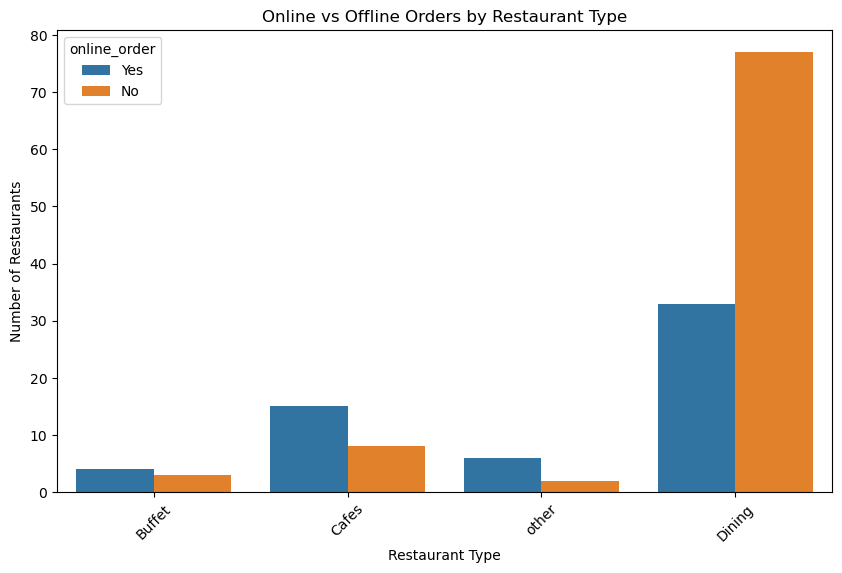

In [19]:
plt.figure(figsize=(10,6))

sns.countplot(
    x="listed_in(type)",
    hue="online_order",
    data=df
)

plt.title("Online vs Offline Orders by Restaurant Type")
plt.xlabel("Restaurant Type")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)

plt.show()

### Dining restaurants primarily accept offline orders whereas cafes accept online orders